# เติมยุค (`PERIODFROM`) จากชนิดซากที่พบ: Similarity vs Taxonomic vs Hybrid

ซากชนิดเดียวกัน (หรือสกุลเดียวกัน) มักมาจากยุคเดียวกัน จึงทายยุคของแหล่งที่ว่างได้จาก**ชื่อวิทยาศาสตร์ของซากในแหล่งนั้น**
โดยดูว่าชื่อเดียวกันหรือคล้ายกันเคยพบในยุคไหนในข้อมูลที่รู้ยุคแล้ว

| วิธี | จับคู่ชื่ออย่างไร |
|---|---|
| **S: Similarity-Based** | เทียบชื่อ**ชนิด** (`Genus species`) ด้วย fuzzy string similarity (`rapidfuzz`) ≥ threshold รวมถึงชื่อที่ตรงตัว |
| **G: Taxonomic-Based** | เทียบชื่อ**สกุล** (`Genus`) ตรงตัว |
| **H: Hybrid** | ลองชนิดตรงตัวก่อน → ไม่เจอใช้ชนิดแบบ fuzzy → ไม่เจออีกใช้สกุล |

**ซากของแต่ละแหล่งมาจาก**
- ตัวอย่างในทะเบียนที่เชื่อมกับแหล่งไว้ใน notebook 02 (เฉพาะความเชื่อมั่น `high` / `medium`)
- ชื่อละตินในคำบรรยายแหล่ง (`FOS_DES_TH`)

**ข้อมูลอ้างอิง (รู้ยุคแล้ว)**: แหล่งของ ทธ. ที่มี `PERIODFROM` และ occurrence ของ PBDB ในไทย (`max_ma`/`min_ma`)

**ทายยุคอย่างไร**: ทุกหน่วยอ้างอิง (แหล่งหรือ collection) ที่มีชื่อตรงกันโหวตให้ยุคของตัวเอง ยุคที่ได้คะแนนมากสุดคือคำตอบ
และสัดส่วนคะแนนของยุคนั้นคือ `vote_share` (ใช้บอกความเชื่อมั่น)

**วัดผล** ด้วย leave-one-out บน 2 ชุด
1. แหล่งของ ทธ. ที่รู้ยุค (ตรงกับงานจริง แต่มีไม่มาก)
2. collection ของ PBDB ในไทย (ชุดใหญ่ ใช้ยืนยันว่าผลไม่ได้มาจากความบังเอิญ)

In [1]:
import re
import unicodedata
from collections import defaultdict
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from rapidfuzz import fuzz, process

DATA = Path("../data")
OUT = DATA / "processed"

_installed = {f.name for f in font_manager.fontManager.ttflist}
THAI_FONT = next((f for f in ["Tahoma", "Thonburi", "Noto Sans Thai", "Leelawadee UI", "Loma", "Garuda"] if f in _installed), None)
plt.rcParams.update({
    "font.family": [THAI_FONT, "DejaVu Sans"] if THAI_FONT else ["DejaVu Sans"], "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.max_columns", 40, "display.max_colwidth", 60, "display.width", 160)
INK, MUTED = "#52514e", "#8a8984"
METHOD_COLOR = {"Baseline": "#bdbcb6", "S": "#2a78d6", "G": "#1baf7a", "H": "#eb6834"}

## 1. ยุคทางธรณีวิทยาและการแยกชื่อวิทยาศาสตร์

In [2]:
PERIODS = [("Precambrian", 4600, 538.8), ("Cambrian", 538.8, 485.4), ("Ordovician", 485.4, 443.8),
           ("Silurian", 443.8, 419.2), ("Devonian", 419.2, 358.9), ("Carboniferous", 358.9, 298.9),
           ("Permian", 298.9, 251.902), ("Triassic", 251.902, 201.4), ("Jurassic", 201.4, 143.1),
           ("Cretaceous", 143.1, 66.0), ("Tertiary", 66.0, 2.58), ("Quaternary", 2.58, 0.0)]
ORDER = [p for p, _, _ in PERIODS]
RANK = {p: i for i, p in enumerate(ORDER)}
TH_NAME = {"Precambrian": "พรีแคมเบรียน", "Cambrian": "แคมเบรียน", "Ordovician": "ออร์โดวิเชียน", "Silurian": "ไซลูเรียน",
           "Devonian": "ดีโวเนียน", "Carboniferous": "คาร์บอนิเฟอรัส", "Permian": "เพอร์เมียน", "Triassic": "ไทรแอสซิก",
           "Jurassic": "จูแรสซิก", "Cretaceous": "ครีเทเชียส", "Tertiary": "เทอร์เชียรี", "Quaternary": "ควอเทอร์นารี"}
PERIOD_TH = {
    "Cambrian": r"แคมเบรียน", "Ordovician": r"ออร์โด", "Silurian": r"ไซลูเรียน", "Devonian": r"ดีโวเนียน",
    "Carboniferous": r"คาร์บอนิเฟอรัส", "Permian": r"เพอร์เมียน", "Triassic": r"ไทรแอส", "Jurassic": r"จู(?:แร|รา)ส",
    "Cretaceous": r"ครีเท", "Tertiary": r"เทอร์เชียรี|นีโอจีน|พาลีโอจีน|ไมโอซีน|ไพลโอซีน|โอลิโกซีน|อีโอซีน",
    "Quaternary": r"ควอเทอร์นารี|ไพลสโตซีน|โฮโลซีน",
}


def period_at(ma, side):
    for p, base, top in PERIODS:
        if (side == "old" and top < ma <= base) or (side == "young" and top <= ma < base):
            return p
    return None


def parse_period_th(text):
    if not isinstance(text, str):
        return (None, None)
    found = sorted((p for p, pat in PERIOD_TH.items() if re.search(pat, text)), key=RANK.get)
    return (found[0], found[-1]) if found else (None, None)


def clean_th(s):
    if not isinstance(s, str):
        return s
    s = unicodedata.normalize("NFC", s).replace("ํา", "ำ")
    return re.sub(r"\s+", " ", s).strip()


# ชื่อไม่เป็นทางการ/กลุ่มกว้างที่ไม่ใช่ชื่อสกุล
INFORMAL = {"Sauropod", "Theropod", "Dinosaur", "Shark", "Turtle", "Coral", "Coprolite", "Phytosaur", "Ooids", "Trilobites",
            "Prosauropod", "Sinraptorid", "Rhychonellacean", "Fusulinid", "Crocodile", "Brachiopod", "Ammonite", "Bivalve",
            "Gastropod", "Productid", "Rugosa", "Tabulata", "Plant"}
# ชื่อระดับสูงกว่าสกุลที่รูปคำเหมือนสกุล และชื่อสกุลที่สะกดผิด (ชุดเดียวกับ feature_lib.HIGHER_TAXA / GENUS_FIX — พบตอนตรวจทาน)
HIGHER_TAXA = {"Ruminantia", "Primates", "Rodentia", "Crocodilia", "Cnidaria", "Sauropoda", "Proboscidea", "Actinopterygii",
               "Bryozoa", "Trionychia", "Testudines", "Theropoda", "Ornithopoda", "Mammalia", "Reptilia", "Brachiopoda", "Mollusca"}
GENUS_FIX = {"Spinomatinia": "Spinomartinia", "Cetopangasis": "Cetopangasius", "Stenocisma": "Stenoscisma", "Orthoticia": "Orthotichia",
             "Phricodothynis": "Phricodothyris", "Neoschwaqerina": "Neoschwagerina", "Squemularia": "Squamularia",
             "Steinmanias": "Steinmannia", "Pseudofusulinid": "Pseudofusulina"}
QUALIFIERS = {"cf.", "cf", "aff.", "aff", "n.", "nov.", "gen.", "sp.nov.", "?"}
NOT_EPITHET = {"sp", "sp.", "spp.", "isp.", "indet", "indet.", "or", "and", "gen", "et"}


def parse_taxon(name):
    # คืน (genus, binomial หรือ None) หรือ None ถ้าไม่ใช่ชื่อระดับสกุล/ชนิด
    if not isinstance(name, str) or name.lstrip("์").startswith("N/A"):
        return None
    toks = [t for t in re.sub(r"[\"'()\[\]?,]", " ", name).split() if t.lower() not in QUALIFIERS]
    if not toks:
        return None
    g = GENUS_FIX.get(toks[0], toks[0])
    # ลงท้าย -id (Stegosaurid, Pectinid) = ชื่อเรียกระดับวงศ์แบบไม่เป็นทางการ ไม่ใช่สกุล (เหมือน feature_lib.parse_taxon)
    if not re.fullmatch(r"[A-Z][a-z]{2,}", g) or g in INFORMAL or g in HIGHER_TAXA or re.search(r"(idae|inae|oidea|formes|acea|ida|id)$", g):
        return None
    ep = toks[1] if len(toks) > 1 else None
    if ep and re.fullmatch(r"[a-z][a-z\-]{2,}", ep) and ep not in NOT_EPITHET:
        return (g, f"{g} {ep}")
    return (g, None)


def latin_in_text(text):
    # ชื่อละตินในคำบรรยายภาษาไทย เช่น 'ภูเวียงโกซอรัส สิรินธรเน (Phuwiangosaurus sirindhornae)'
    if not isinstance(text, str):
        return []
    out = []
    for g, ep in re.findall(r"\b([A-Z][a-z]{2,})(?:\s+(?:cf\.\s*)?([a-z]{3,}))?", text):
        t = parse_taxon(f"{g} {ep}".strip())
        if t:
            out.append(t)
    return out


for n in ["Phuwiangosaurus sirindhornae", "cf. Asianopodus isp.", "?Siamosuchus phuphokensis", "Sauropod",
          "Fusulinida indet.", "Linoproductus sp.", "N/A (Dinosaur)", "Trachypithecus sp. or Presbytis sp."]:
    print(f"{n:40s} -> {parse_taxon(n)}")

Phuwiangosaurus sirindhornae             -> ('Phuwiangosaurus', 'Phuwiangosaurus sirindhornae')
cf. Asianopodus isp.                     -> ('Asianopodus', None)
?Siamosuchus phuphokensis                -> ('Siamosuchus', 'Siamosuchus phuphokensis')
Sauropod                                 -> None
Fusulinida indet.                        -> None
Linoproductus sp.                        -> ('Linoproductus', None)
N/A (Dinosaur)                           -> None
Trachypithecus sp. or Presbytis sp.      -> ('Trachypithecus', None)


## 2. สร้างตารางซากต่อหน่วย

หน่วย (`unit`) คือแหล่งของ ทธ. (`dmr:<OBJECTID>`) หรือ collection ของ PBDB (`pbdb:<collection_no>`)
แต่ละแถว = 1 ชื่อซากในหน่วยนั้น พร้อมยุคของหน่วย (ถ้ารู้)

In [3]:
sites = gpd.read_file(DATA / "dmr_fossil_sites" / "fossil_sites.geojson")
for c in ["NAME_TH", "PROVINCE", "PERIODFROM", "FOS_DES_TH"]:
    sites[c] = sites[c].map(clean_th).replace({"": None})
sites["OBJECTID"] = sites.OBJECTID.astype(int)
sites[["rec_old", "rec_young"]] = sites.PERIODFROM.map(parse_period_th).tolist()
site_label = sites.set_index("OBJECTID")[["rec_old", "rec_young"]]

# ซากจากทะเบียนตัวอย่างที่เชื่อมแหล่งไว้ (notebook 02): ใช้ high/medium และกระจายให้ทุกแหล่งที่เสมอกัน
merged = pd.read_csv(OUT / "fossil_list_merged.csv", dtype={"fossil_id": str, "SITE_CODE": str, "site_SITE_CODE": str, "site_OBJECTID": "Int64"}, encoding="utf-8-sig", low_memory=False)
links = merged[merged.confidence.isin(["high", "medium"])][["fossil_id", "sci_name", "tied_site_ids"]].copy()
links["OBJECTID"] = links.tied_site_ids.str.split(";")
links = links.explode("OBJECTID").assign(OBJECTID=lambda d: d.OBJECTID.astype(float).astype(int))
links["taxon"] = links.sci_name.map(parse_taxon)

dmr_rows = [("dmr:%d" % o, t[0], t[1], "specimen") for o, t in zip(links.OBJECTID, links.taxon) if t]
dmr_rows += [("dmr:%d" % o, g, b, "site description") for o, txt in zip(sites.OBJECTID, sites.FOS_DES_TH) for g, b in latin_in_text(txt)]
dmr = pd.DataFrame(dmr_rows, columns=["unit", "genus", "binomial", "from"]).drop_duplicates(["unit", "genus", "binomial"])
oid = dmr.unit.str[4:].astype(int)
dmr["old"] = oid.map(site_label.rec_old)
dmr["young"] = oid.map(site_label.rec_young)

occs = pd.read_csv(DATA / "pbdb_thailand" / "occurrences.csv", low_memory=False)
occs["taxon"] = occs.identified_name.map(parse_taxon)
occs.loc[occs.taxon.isna(), "taxon"] = occs.loc[occs.taxon.isna(), "accepted_name"].map(parse_taxon)
pb = occs.dropna(subset=["taxon"])
pbdb = pd.DataFrame({"unit": "pbdb:" + pb.collection_no.astype(str), "genus": pb.taxon.str[0], "binomial": pb.taxon.str[1],
                     "from": "pbdb occurrence", "old": pb.max_ma.map(lambda a: period_at(a, "old")),
                     "young": pb.min_ma.map(lambda a: period_at(a, "young"))}).drop_duplicates(["unit", "genus", "binomial"])

taxa = pd.concat([dmr, pbdb], ignore_index=True)
taxa["labeled"] = taxa.old.notna()
REF = taxa[taxa.labeled].reset_index(drop=True)

dmr_units = dmr.groupby("unit").agg(labeled=("old", lambda s: s.notna().any()), n_taxa=("genus", "size"))
print(f"แหล่ง ทธ. ที่มีชื่อซาก: {len(dmr_units)} (รู้ยุค {dmr_units.labeled.sum()} | ว่าง {(~dmr_units.labeled).sum()})")
print(f"   แหล่งที่ว่างทั้งหมด {sites.rec_old.isna().sum()} → มีชื่อซากให้ทาย {(~dmr_units.labeled).sum()}")
print(f"collection PBDB ที่มีชื่อซาก: {pbdb.unit.nunique()}")
print(f"ตารางอ้างอิง: {len(REF):,} แถว | สกุล {REF.genus.nunique():,} | ชนิด {REF.binomial.nunique():,}")
taxa.groupby("from").agg(rows=("genus", "size"), units=("unit", "nunique"), with_species=("binomial", lambda s: s.notna().mean())).style.format({"with_species": "{:.0%}"})

แหล่ง ทธ. ที่มีชื่อซาก: 194 (รู้ยุค 48 | ว่าง 146)
   แหล่งที่ว่างทั้งหมด 352 → มีชื่อซากให้ทาย 146
collection PBDB ที่มีชื่อซาก: 673
ตารางอ้างอิง: 4,765 แถว | สกุล 1,265 | ชนิด 1,240


,rows,units,with_species
from,,,
pbdb occurrence,4531,673,66%
site description,88,54,35%
specimen,682,157,53%


## 3. ตัวทายยุค

1. หา**หน่วยอ้างอิง**ที่มีชื่อตรงกับซากของหน่วยเป้าหมาย ตามวิธีที่เลือก (ไม่นับตัวเอง: leave-one-out)
2. แต่ละหน่วยอ้างอิงโหวต 1 เสียง (ถ่วงด้วยคะแนนความคล้ายสำหรับ fuzzy) กระจายเท่ากันให้ทุกยุคในช่วงอายุของมัน
   (หน่วยที่มีช่วง เพอร์เมียน–ไทรแอสซิก ให้ยุคละครึ่งเสียง)
3. ยุคที่ได้คะแนนสูงสุดคือคำตอบ, `vote_share` = คะแนนของยุคนั้น / คะแนนรวม

ความคล้ายของชนิดคำนวณล่วงหน้าระหว่างชื่อชนิดที่ไม่ซ้ำกันทั้งหมด (`rapidfuzz.process.cdist`, `fuzz.ratio`)

In [4]:
all_binomials = sorted(set(taxa.binomial.dropna()))
ref_binomials = sorted(set(REF.binomial.dropna()))
sim = process.cdist(all_binomials, ref_binomials, scorer=fuzz.ratio, dtype=np.uint8, workers=-1)
B_IDX = {b: i for i, b in enumerate(all_binomials)}
SIMILAR = {}  # binomial -> [(ref_binomial, score)] ที่ score >= 80
for b, i in B_IDX.items():
    js = np.nonzero(sim[i] >= 80)[0]
    SIMILAR[b] = [(ref_binomials[j], int(sim[i, j])) for j in js]

REF_BY_BINOMIAL = {k: g[["unit", "old", "young"]].values for k, g in REF.dropna(subset=["binomial"]).groupby("binomial")}
REF_BY_GENUS = {k: g[["unit", "old", "young"]].values for k, g in REF.groupby("genus")}
UNIT_TAXA = {u: g[["genus", "binomial"]].values for u, g in taxa.groupby("unit")}


def matches(unit, level, T):
    # คืน dict: หน่วยอ้างอิง -> (old, young, weight, หลักฐาน)
    hits = {}
    for genus, binomial in UNIT_TAXA[unit]:
        if level in ("exact", "fuzzy") and isinstance(binomial, str):
            cands = [(binomial, 100)] if level == "exact" else [(b, s) for b, s in SIMILAR.get(binomial, []) if T <= s < 100]
            for rb, score in cands:
                for ru, o, y in REF_BY_BINOMIAL.get(rb, []):
                    if ru != unit and (ru not in hits or hits[ru][2] < score / 100):
                        hits[ru] = (o, y, score / 100, f"{binomial}≈{rb} ({score})" if score < 100 else binomial)
        if level == "genus":
            for ru, o, y in REF_BY_GENUS.get(genus, []):
                if ru != unit and ru not in hits:
                    hits[ru] = (o, y, 1.0, genus)
    return hits


def vote(hits):
    acc = defaultdict(float)
    for o, y, w, _ in hits.values():
        span = RANK[y] - RANK[o] + 1
        for k in range(RANK[o], RANK[y] + 1):
            acc[ORDER[k]] += w / span
    best = max(acc, key=acc.get)
    return best, acc[best] / sum(acc.values())


def predict(unit, method, T=90):
    # คืน (period, vote_share, level, n_ref_units, evidence)
    if method == "S":
        plan = [("exact+fuzzy", None)]
    elif method == "G":
        plan = [("genus", None)]
    else:
        plan = [("exact", None), ("fuzzy", None), ("genus", None)]
    for level, _ in plan:
        if level == "exact+fuzzy":
            hits = matches(unit, "exact", T)
            for k, v in matches(unit, "fuzzy", T).items():
                hits.setdefault(k, v)
        else:
            hits = matches(unit, level, T)
        if hits:
            p, share = vote(hits)
            ev = sorted({h[3] for h in hits.values()})
            return p, share, level, len(hits), "; ".join(ev[:4])
    return None, np.nan, "none", 0, ""


# ตัวอย่าง: แหล่ง ทธ. ที่รู้ยุคและมีชื่อซาก 3 แหล่งแรก (ทายโดยไม่ใช้ข้อมูลของตัวเอง)
for u in [u for u, r in dmr_units.iterrows() if r.labeled][:3]:
    ex = sites.loc[sites.OBJECTID.eq(int(u[4:])), ["NAME_TH", "PERIODFROM"]].iloc[0]
    print(f"{ex.NAME_TH} | บันทึก: {ex.PERIODFROM} | H ทาย: {predict(u, 'H')}")

สัตว์ไม่มีกระดูกสันหลัง ถ้ำฤาษี - ถ้ำลูกเสือ | บันทึก: เพอร์เมียน | H ทาย: ('Permian', 0.6666666666666666, 'genus', 3, 'Syringopora')
แหล่งซากไดโนเสาร์ภูกุ้มข้าว จังหวัดกาฬสินธุ์ | บันทึก: ครีเทเชียสตอนต้น | H ทาย: ('Cretaceous', 1.0, 'exact', 15, 'Phuwiangosaurus sirindhornae; Siamosaurus suteethorni')
สัตว์มีกระดูกสันหลังถ้ำวิมารนาคิน | บันทึก: เพอร์เมียน | H ทาย: ('Quaternary', 0.8, 'exact', 5, 'Ailuropoda melanoleuca; Bos gaurus; Rusa unicolor')


## 4. วัดผลด้วย leave-one-out

นับว่า**ถูก**เมื่อยุคที่ทายอยู่ในช่วงยุคจริงของหน่วยนั้น
- `coverage`: สัดส่วนหน่วยที่ทายได้ (มีชื่อตรงกับหน่วยอ้างอิงอย่างน้อย 1 หน่วย)
- `accuracy`: ความถูกต้องในหน่วยที่ทายได้
- `effective`: = coverage × accuracy (สัดส่วนหน่วยทั้งหมดที่ได้คำตอบถูก) ← ใช้เลือกวิธี
- `Baseline`: ทายยุคที่พบบ่อยที่สุดในข้อมูลอ้างอิงเสมอ

In [5]:
def true_range(unit):
    g = taxa[taxa.unit.eq(unit)].iloc[0]
    return g.old, g.young


EVAL = {"DMR sites": [u for u, r in dmr_units.iterrows() if r.labeled],
        "PBDB collections": sorted(set(pbdb.loc[pbdb.old.notna(), "unit"]))}
TRUE = {u: true_range(u) for us in EVAL.values() for u in us}
majority = REF.drop_duplicates("unit").old.value_counts().idxmax()


def evaluate(method, units, T=90):
    rows = []
    for u in units:
        o, y = TRUE[u]
        if method == "Baseline":
            p, share, level = majority, np.nan, "baseline"
        else:
            p, share, level, _, _ = predict(u, method, T)
        rows.append((u, p, share, level, (RANK[o] <= RANK[p] <= RANK[y]) if p else np.nan))
    return pd.DataFrame(rows, columns=["unit", "pred", "share", "level", "correct"])


per_unit = {(name, m): evaluate(m, units) for name, units in EVAL.items() for m in ["Baseline", "S", "G", "H"]}
summary = pd.DataFrame([{
    "eval set": name, "method": m, "n": len(r), "coverage": r.pred.notna().mean(),
    "accuracy": r.correct.mean(), "effective": r.correct.fillna(False).astype(bool).mean(),
} for (name, m), r in per_unit.items()])
print(f"Baseline ทาย '{majority}' เสมอ")
summary.pivot(index="method", columns="eval set", values=["coverage", "accuracy", "effective"]).reindex(["Baseline", "S", "G", "H"]).style.format("{:.1%}")

Baseline ทาย 'Permian' เสมอ


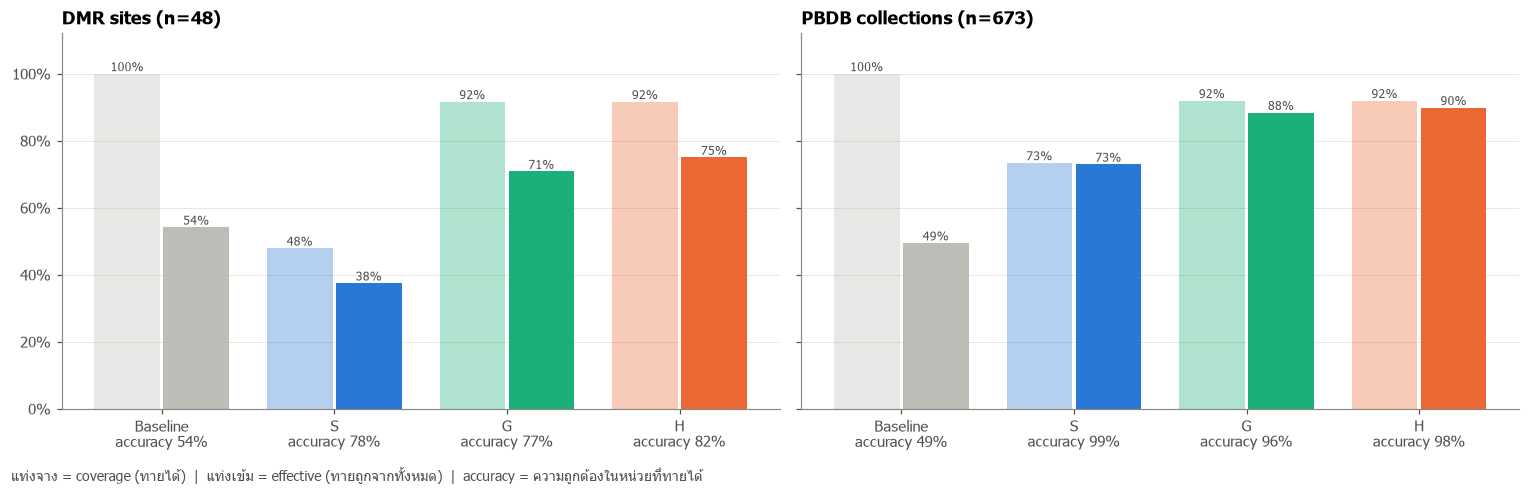

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3), sharey=True)
for ax, name in zip(axes, EVAL):
    sm = summary[summary["eval set"].eq(name)].set_index("method").reindex(["Baseline", "S", "G", "H"])
    x = np.arange(len(sm))
    ax.bar(x - 0.2, sm.coverage, width=0.38, color=[METHOD_COLOR[m] for m in sm.index], alpha=0.35, label="coverage")
    ax.bar(x + 0.2, sm.effective, width=0.38, color=[METHOD_COLOR[m] for m in sm.index], label="effective (ถูกจากทั้งหมด)")
    for xi, (c, e) in enumerate(zip(sm.coverage, sm.effective)):
        ax.text(xi - 0.2, c, f"{c:.0%}", ha="center", va="bottom", fontsize=8, color=INK)
        ax.text(xi + 0.2, e, f"{e:.0%}", ha="center", va="bottom", fontsize=8, color=INK)
    ax.set_xticks(x, [f"{m}\naccuracy {a:.0%}" for m, a in zip(sm.index, sm.accuracy)])
    ax.set_ylim(0, 1.12)
    ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
    ax.set_title(f"{name} (n={sm.n.iat[0]})")
    ax.grid(axis="x", visible=False)
fig.text(0.01, -0.03, "แท่งจาง = coverage (ทายได้)  |  แท่งเข้ม = effective (ทายถูกจากทั้งหมด)  |  accuracy = ความถูกต้องในหน่วยที่ทายได้",
         fontsize=9, color=INK)
plt.tight_layout()

### เลือก threshold ของ fuzzy (วิธี S)

ไล่ threshold ของ `fuzz.ratio` ดูว่า coverage ที่เพิ่มขึ้นแลกกับ accuracy ที่ลดลงแค่ไหน
ชื่อชนิดที่คะแนนต่ำ ๆ มักเป็น**คนละชนิดที่ชื่อบังเอิญคล้ายกัน**

In [7]:
sweep = []
for T in [80, 85, 88, 90, 92, 95, 100]:
    for name, units in EVAL.items():
        r = evaluate("S", units, T)
        sweep.append({"T": T, "eval set": name, "coverage": r.pred.notna().mean(), "accuracy": r.correct.mean(),
                      "effective": r.correct.fillna(False).astype(bool).mean()})
sweep = pd.DataFrame(sweep)
display(sweep.pivot(index="T", columns="eval set", values=["coverage", "accuracy", "effective"]).style.format("{:.1%}"))

pairs = [(b, rb, s) for b in all_binomials for rb, s in SIMILAR[b] if 80 <= s < 100 and b.split()[0] != rb.split()[0]]
print(f"คู่ชนิดที่คล้าย ≥ 80 แต่คนละสกุล: {len(pairs)} ตัวอย่าง:")
for b, rb, s in sorted(pairs, key=lambda x: -x[2])[:12]:
    print(f"  {s:3d}  {b}  ≈  {rb}")

คู่ชนิดที่คล้าย ≥ 80 แต่คนละสกุล: 35 ตัวอย่าง:
   97  Khoratichthy gibbus  ≈  Khoratichthys gibbus
   96  Squamalaria postgrandis  ≈  Squamularia postgrandis
   96  Squamularia postgrandis  ≈  Squamalaria postgrandis
   96  Thaichthys buddhabutensis  ≈  Thaiichthys buddhabutrensis
   96  Triplanospongos musashiensis  ≈  Triplanospongus musashiensis
   96  Triplanospongus musashiensis  ≈  Triplanospongos musashiensis
   94  Squamalaria nodosa  ≈  Squamularia nodosa
   94  Squamularia nodosa  ≈  Squamalaria nodosa
   85  Annulotriassocampe sulovensis  ≈  Triassocampe sulovensis
   85  Conohyus thailandicus  ≈  Progenitohyus thailandicus
   85  Leioclema mongraiensis  ≈  Paralioclema mongraiensis
   85  Paralioclema mongraiensis  ≈  Leioclema mongraiensis


### ความแม่นตามระดับการจับคู่ของ Hybrid และตาม `vote_share`

In [8]:
h = pd.concat([per_unit[(n, "H")].assign(eval_set=n) for n in EVAL])
by_level = h.groupby(["eval_set", "level"]).correct.agg(["size", "mean"]).unstack(0).reindex(["exact", "fuzzy", "genus", "none"])
by_level["size"] = by_level["size"].fillna(0).astype(int)
display(by_level.style.format("{:.0%}", subset=[c for c in by_level.columns if c[0] == "mean"], na_rep="-"))

h["share_bin"] = pd.cut(h.share, [0, 0.5, 0.75, 0.999, 1.0], labels=["≤50%", "50–75%", "75–<100%", "100%"], include_lowest=True)
by_share = h.groupby(["eval_set", "share_bin"], observed=True).correct.agg(["size", "mean"]).unstack(0)
by_share.style.format("{:.0%}", subset=[c for c in by_share.columns if c[0] == "mean"])

## 5. เลือกวิธีและเติมยุค

In [9]:
dmr_sum = summary[summary["eval set"].eq("DMR sites")].set_index("method")
pb_sum = summary[summary["eval set"].eq("PBDB collections")].set_index("method")
best = dmr_sum.drop("Baseline").effective.idxmax()
print("effective สูงสุดบนแหล่ง ทธ.:", best, f"({dmr_sum.at[best, 'effective']:.1%})",
      "| บน PBDB:", pb_sum.drop("Baseline").effective.idxmax(), f"({pb_sum.drop('Baseline').effective.max():.1%})")

effective สูงสุดบนแหล่ง ทธ.: H (75.0%) | บน PBDB: H (89.9%)


### สรุป: เลือก **H (Hybrid)**

| | S: Similarity (ชนิด) | G: Taxonomic (สกุล) | **H: Hybrid** |
|---|---|---|---|
| ทายได้ (แหล่ง ทธ. / PBDB) | 48% / 73% | 92% / 92% | **92% / 92%** |
| ถูกในส่วนที่ทายได้ | 78% / 99% | 77% / 96% | **82% / 98%** |
| ถูกจากทั้งหมด (effective) | 38% / 73% | 71% / 88% | **75% / 90%** |

- **S ครอบคลุมน้อย** เพราะซากราวครึ่งหนึ่งระบุแค่สกุล (`Linoproductus sp.`) ไม่มีชื่อชนิดให้เทียบ ทายได้แม่นแต่ทายได้น้อยแหล่ง
- **G ครอบคลุมเท่า H** (ระดับสกุลเป็นขั้นสุดท้ายของ H) แต่แม่นน้อยกว่า เพราะสกุลเดียวอาจพบได้หลายยุค
- **H ได้ทั้งสองอย่าง**: ใช้ชื่อชนิดก่อนเมื่อมี (แม่นกว่า) และถอยไปสกุลเมื่อไม่มี จึงชนะทั้งบนแหล่ง ทธ. และ PBDB ห่าง baseline (ทายเพอร์เมียนเสมอ) ราว 20–40 จุด
- **ขั้น fuzzy แทบไม่ได้ใช้**: ชื่อชนิดส่วนใหญ่ตรงตัวอยู่แล้ว fuzzy ช่วยแค่กรณีสะกดผิดจริง (`Stenocisma`/`Stenoscisma`, `Thaichthys buddhabutensis`/`Thaiichthys buddhabutrensis`)
  และ threshold 80–100 ให้ผลแทบเท่ากัน จึงใช้ 90 เพื่อกันคู่ที่เป็นคนละชนิด (`Conohyus thailandicus` ≈ `Progenitohyus thailandicus` ได้ 85)
- **`vote_share` ใช้บอกความเชื่อมั่นได้จริง**: ถ้าโหวตเป็นเอกฉันท์ (100%) ถูก 93% บนแหล่ง ทธ. ถ้า ≤ 75% ความแม่นลดลงชัดเจน

ข้อควรระวัง: ตัวเลขบน PBDB สูงเกินจริงไปบ้าง เพราะ collection ที่มาจากงานตีพิมพ์เดียวกันมักมีชนิดและยุคซ้ำกัน ชุดแหล่ง ทธ. (n=48) ใกล้เคียงงานจริงกว่า

In [10]:
def confidence(level, share):
    if level == "none":
        return None
    strong = share >= 0.75
    if level == "exact":
        return "high" if strong else "medium"
    if level == "fuzzy":
        return "medium" if strong else "low"
    return "medium" if strong else "low"  # genus


target_units = [u for u, r in dmr_units.iterrows() if not r.labeled]
rows = []
for u in target_units:
    rec = {"OBJECTID": int(u[4:])}
    for m in ["S", "G", "H"]:
        p, share, level, n, ev = predict(u, m)
        rec[f"pred_{m}"] = p
        if m == "H":
            rec.update(hybrid_level=level, vote_share=round(share, 3) if p else np.nan, n_ref_units=n, evidence=ev)
    rows.append(rec)
fill = pd.DataFrame(rows)
fill["period_confidence"] = [confidence(l, s) for l, s in zip(fill.hybrid_level, fill.vote_share)]
fill["PERIODFROM_filled_taxon"] = fill.pred_H.map(TH_NAME)

print(f"แหล่งที่ว่าง {sites.rec_old.isna().sum()} | มีชื่อซาก {len(fill)} | เติมได้ (H) {fill.pred_H.notna().sum()}")
display(pd.crosstab(fill.hybrid_level, fill.period_confidence.fillna("-")).reindex(["exact", "fuzzy", "genus", "none"], fill_value=0))
fill.merge(sites[["OBJECTID", "NAME_TH", "PROVINCE"]], on="OBJECTID").dropna(subset=["pred_H"]).sort_values(
    ["hybrid_level", "vote_share"], ascending=[True, False])[["NAME_TH", "PROVINCE", "pred_S", "pred_G", "pred_H", "hybrid_level", "vote_share", "evidence"]].head(15)

แหล่งที่ว่าง 352 | มีชื่อซาก 146 | เติมได้ (H) 117


period_confidence,-,high,low,medium
hybrid_level,,,,
exact,0,48,0,7
fuzzy,0,0,0,0
genus,0,0,10,52
none,29,0,0,0


,NAME_TH,PROVINCE,pred_S,pred_G,pred_H,hybrid_level,vote_share,evidence
1,ไดโนเสาร์ภูผางั่ว,กาฬสินธุ์,Cretaceous,Cretaceous,Cretaceous,exact,1.0,Phuwiangosaurus sirindhornae
3,ไดโนเสาร์โคกโก่ง,กาฬสินธุ์,Cretaceous,Cretaceous,Cretaceous,exact,1.0,Phuwiangosaurus sirindhornae
4,ไดโนเสาร์ภูสิงห์,กาฬสินธุ์,Cretaceous,Cretaceous,Cretaceous,exact,1.0,Isanemys srisuki
7,สัตว์ไม่มีกระดูกสันหลังอ่าวสน,สตูล,Cambrian,Cambrian,Cambrian,exact,1.0,Thailandium solum
13,บ้านสะพานหิน แปลง 2011,นครราชสีมา,Cretaceous,Cretaceous,Cretaceous,exact,1.0,Khoratamia phattharajani; Kizylkumemys khoratensis; Siam...
14,บ้านสะพานหิน แปลง 2009,นครราชสีมา,Cretaceous,Cretaceous,Cretaceous,exact,1.0,Khoratamia phattharajani; Kizylkumemys khoratensis; Siam...
16,บ้านสะพานหิน แปลง 2008,นครราชสีมา,Cretaceous,Cretaceous,Cretaceous,exact,1.0,Khoratamia phattharajani; Kizylkumemys khoratensis; Siam...
17,เอปโคราช,นครราชสีมา,Tertiary,Tertiary,Tertiary,exact,1.0,Khoratpithecus piriyai
20,สัตว์ไม่มีกระดูกสันหลังอ่าวตะโล๊ะอุดัง,สตูล,Cambrian,Permian,Cambrian,exact,1.0,Thailandium solum
21,สัตว์เลี้ยงลูกด้วยนมบ้านสระ,พะเยา,Tertiary,Quaternary,Tertiary,exact,1.0,Conohyus sindiensis; Propotamochoerus hysudricus


### เทียบกับการเติมจาก PBDB ที่อยู่ใกล้ (notebook 03)

ทั้งสองวิธีใช้หลักฐานต่างกัน (ชนิดซาก vs ระยะทาง) ถ้าได้ยุคตรงกัน ค่าที่เติมก็น่าเชื่อถือขึ้น

In [11]:
p03 = OUT / "sites_period_filled.csv"
if p03.exists():
    nb03 = pd.read_csv(p03, encoding="utf-8-sig")[["OBJECTID", "period_source", "period_old", "period_young", "period_confidence"]]
    cmp_ = fill.dropna(subset=["pred_H"]).merge(nb03.rename(columns={"period_confidence": "conf_03"}), on="OBJECTID")
    both = cmp_[cmp_.period_source.isin(["PBDB taxon", "PBDB nearby"])].copy()
    both["agree"] = [RANK[o] <= RANK[p] <= RANK[y] for p, o, y in zip(both.pred_H, both.period_old, both.period_young)]
    print(f"แหล่งที่ทั้ง 04 และ 03 เติมได้: {len(both)} | ตรงกัน {both.agree.mean():.0%}")
    print(f"แหล่งที่ 04 เติมได้แต่ 03 เติมไม่ได้: {cmp_.period_source.eq('missing').sum()}")
    display(both.groupby(["hybrid_level"]).agree.agg(["size", "mean"]).reindex(["exact", "fuzzy", "genus"]).fillna({"size": 0})
            .style.format({"mean": "{:.0%}", "size": "{:.0f}"}, na_rep="-"))
else:
    print("ไม่พบผลของ notebook 03 จึงข้ามการเทียบ")

แหล่งที่ทั้ง 04 และ 03 เติมได้: 86 | ตรงกัน 80%
แหล่งที่ 04 เติมได้แต่ 03 เติมไม่ได้: 31


,size,mean
hybrid_level,,
exact,47,85%
fuzzy,0,-
genus,39,74%


## 6. บันทึกผล

`data/processed/sites_period_filled_taxon.csv` / `.geojson`: แหล่งทั้ง 518 แห่ง
- `PERIODFROM` เดิม (ไม่แก้), `PERIODFROM_filled_taxon` (ภาษาไทย, จากวิธีที่เลือก)
- `pred_S`, `pred_G`, `pred_H`: คำทายของแต่ละวิธี (ไว้เปรียบเทียบ)
- `hybrid_level` (exact / fuzzy / genus), `vote_share`, `n_ref_units`, `evidence` (ชื่อที่ใช้จับคู่), `period_confidence`

`data/processed/eval_taxon_hybrid_loo.csv`: ผล leave-one-out ของ H บนแหล่ง ทธ. ที่รู้ยุค (ใช้ใน notebook 05)

In [12]:
res = sites[["OBJECTID", "SITE_CODE", "NAME_TH", "PROVINCE", "PERIODFROM", "geometry"]].merge(fill, on="OBJECTID", how="left")
res["PERIODFROM_filled_taxon"] = res.PERIODFROM.where(res.PERIODFROM.notna(), res.PERIODFROM_filled_taxon)
res["period_source_taxon"] = np.select([res.PERIODFROM.notna(), res.pred_H.notna()], ["DMR record", "taxon " + res.hybrid_level.fillna("")], "missing")
res = gpd.GeoDataFrame(res, geometry="geometry", crs=4326)
res.to_file(OUT / "sites_period_filled_taxon.geojson", driver="GeoJSON")
res.drop(columns="geometry").assign(longitude=res.geometry.x, latitude=res.geometry.y).to_csv(
    OUT / "sites_period_filled_taxon.csv", index=False, encoding="utf-8-sig")
before, after = res.PERIODFROM.isna().sum(), res.PERIODFROM_filled_taxon.isna().sum()
print(f"PERIODFROM ว่าง: {before} → {after} แหล่ง (เติม {before - after})")
# ผล leave-one-out ของ H บนแหล่ง ทธ. ที่รู้ยุค ไว้ใช้วัดความแม่นตอนรวมผล (notebook 05)
loo = per_unit[("DMR sites", "H")].copy()
loo["OBJECTID"] = loo.unit.str[4:].astype(int)
loo["period_confidence"] = [confidence(l, s) for l, s in zip(loo.level, loo.share)]
loo.drop(columns="unit").to_csv(OUT / "eval_taxon_hybrid_loo.csv", index=False, encoding="utf-8-sig")
res.period_source_taxon.value_counts().to_frame("แหล่ง")

PERIODFROM ว่าง: 352 → 235 แหล่ง (เติม 117)


,แหล่ง
period_source_taxon,
missing,235
DMR record,166
taxon genus,62
taxon exact,55


## 7. ข้อจำกัด

- **ซากของแหล่งได้มาจากการ merge ใน notebook 02** ซึ่งไม่แน่นอน 100% (ใช้แค่ high/medium) ถ้าตัวอย่างถูกเชื่อมผิดแหล่ง ยุคที่ทายก็ผิดตาม
- **สกุลที่อยู่หลายยุค** (เช่น หอยหรือแบรคิโอพอดบางสกุล) ทำให้คะแนนโหวตกระจาย ดู `vote_share` ประกอบ
- **`PERIODFROM` ของ ทธ. บางแหล่งเป็นอายุหิน** (เช่น ถ้ำในหินปูน) ซึ่งไม่ตรงกับอายุซาก ความแม่นบนชุด DMR จึงต่ำกว่าความจริงเล็กน้อย
- **fuzzy ของชื่อชนิดจับคู่ตัวอักษร ไม่ได้รู้อนุกรมวิธาน**: ชื่อที่สะกดคล้ายแต่เป็นคนละสกุลจะถูกนับว่าคล้าย (ดูตัวอย่างในส่วน threshold)